In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('/content/USA_Housing.csv')
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB


In [ ]:
df.shape

(5000, 7)

In [ ]:
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


In [ ]:
df.isnull().sum()

,0
Avg. Area Income,0
Avg. Area House Age,0
Avg. Area Number of Rooms,0
Avg. Area Number of Bedrooms,0
Area Population,0
Price,0
Address,0


In [ ]:
df.drop("Address",axis=1,inplace=True)

In [ ]:
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05


In [ ]:
pd.set_option('display.float_format','{:.2f}'.format)

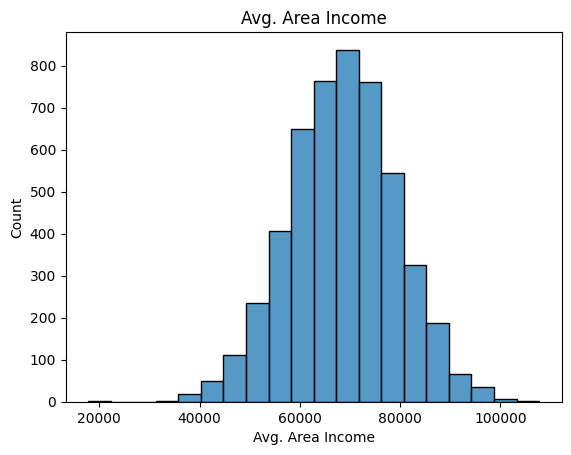

In [ ]:
#Univariate analysis
sns.histplot(df["Avg. Area Income"],bins=20)  #bins=interval
plt.title("Avg. Area Income")
plt.show()

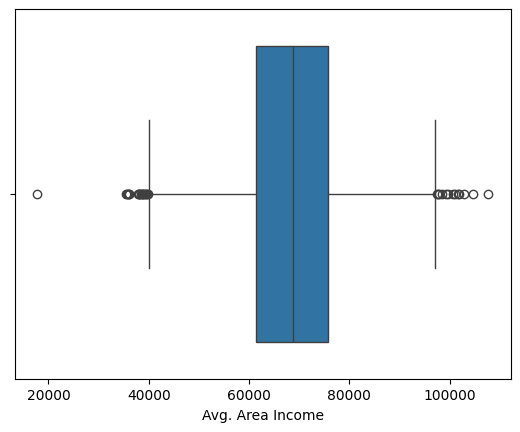

In [ ]:
sns.boxplot(x=df["Avg. Area Income"])
plt.show()

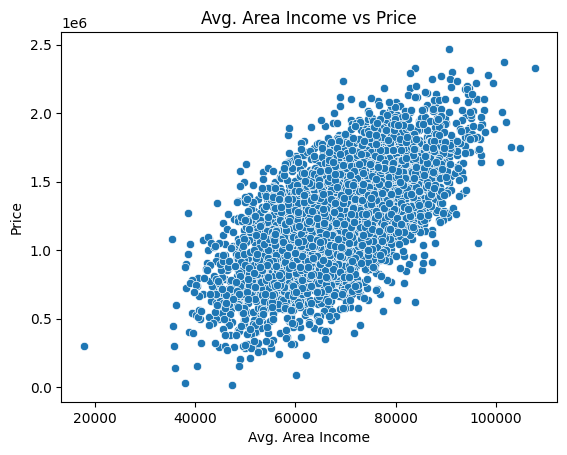

In [ ]:
#Bivariate
sns.scatterplot(x="Avg. Area Income",y="Price",data=df)
plt.title("Avg. Area Income vs Price")
plt.show()

In [ ]:
#Remove Outliers using IQR method
Q1=df["Price"].quantile(0.25)
Q3=df["Price"].quantile(0.75)
IQR=Q3-Q1

lower=Q1-1.5*IQR
upper=Q3+1.5*IQR

df=df[(df["Price"]>=lower) & (df["Price"]<=upper)]


<Axes: xlabel='Price'>

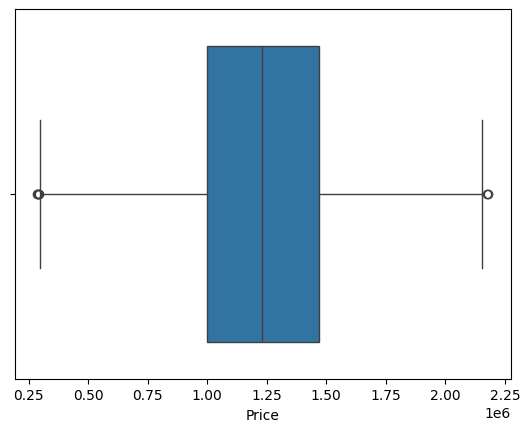

In [ ]:
sns.boxplot(x=df["Price"])

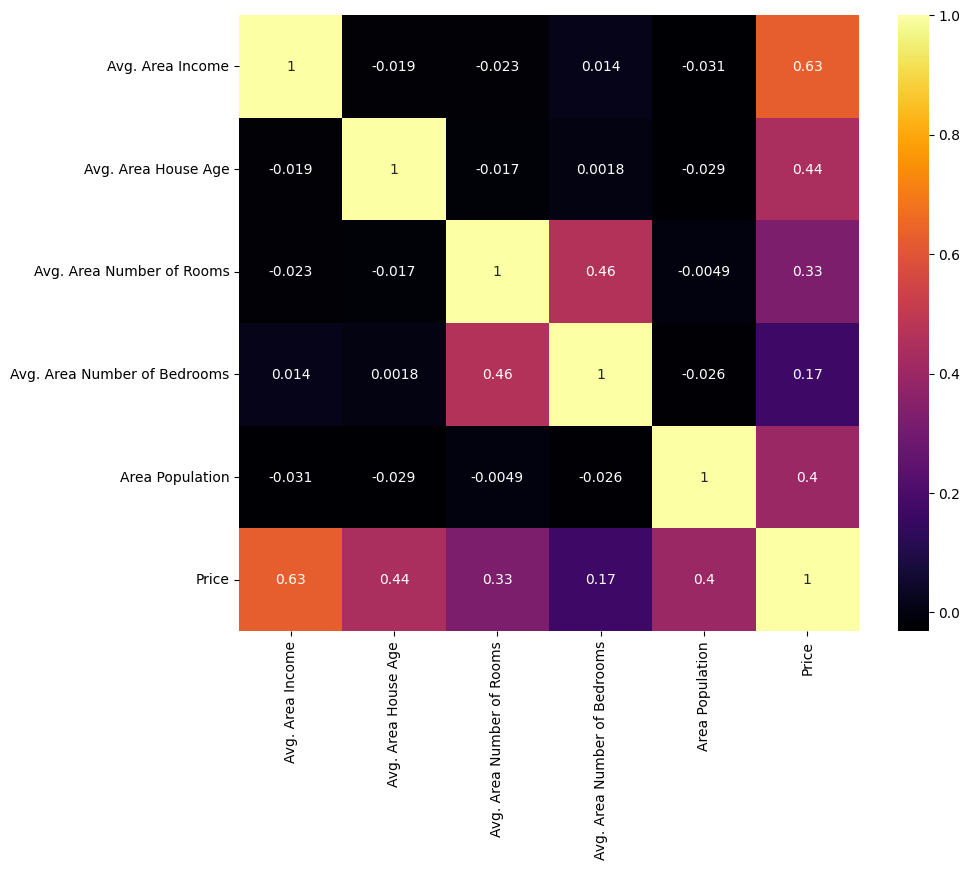

In [ ]:
#Multivaraite analysis heatmap
plt.figure(figsize=(10,8))
numeric_df=df.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(),
            annot=True,
            cmap='inferno')
plt.show()

**Simple Linear Regression**

In [ ]:
#SLR

X=df[["Avg. Area Income"]]
y=df["Price"]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train , y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression

slr_model=LinearRegression()
slr_model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred=slr_model.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

print("Simple Linear Regression")
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("RMSE:",np.sqrt(mean_squared_error(y_test,y_pred)))
print("R2 score:",r2_score(y_test,y_pred))


Simple Linear Regression
MAE: 211937.1651550006
MSE: 69064771104.78278
RMSE: 262801.77150236786
R2 score: 0.3694634636084436


In [ ]:
print("Intercept:",slr_model.intercept_)
print("Slope:"),slr_model.coef_[0]

Intercept: -184980.2982096942
Slope:


(None, np.float64(20.653526141857427))

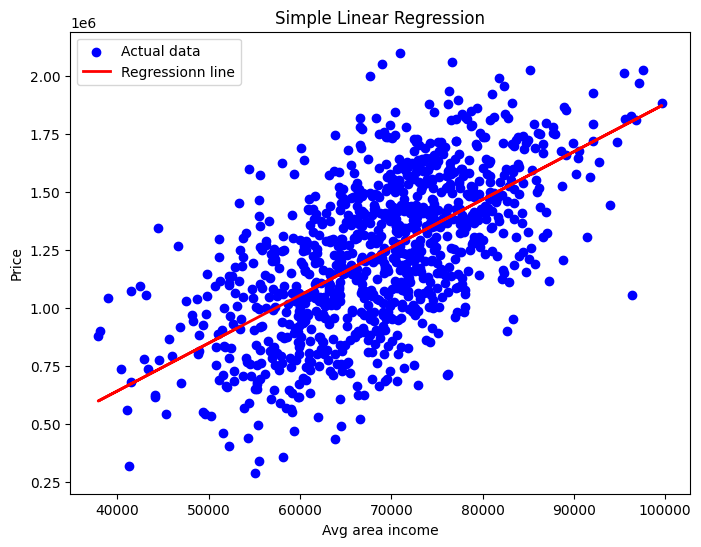

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(X_test,y_test,color='blue',label='Actual data')
plt.plot(X_test,y_pred,color='red',linewidth=2,label='Regressionn line')
plt.xlabel("Avg area income")
plt.ylabel("Price")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

In [ ]:
income=float(input("Enter Average Area income"))
new_data=np.array([[income]])
prediction=slr_model.predict(new_data)
print("Predicted house price=${:,.2f}".format(prediction[0]))

Enter Average Area income240000
Predicted house price=$4,771,865.98


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Hyperparameter Tuning


In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
from sklearn.linear_model import Ridge
ridge=Ridge()
ridge.fit(X_train,y_train)
ridge_pred=ridge.predict(X_test)
print("Default Ridge r2:",r2_score(y_test,ridge_pred))

Default Ridge r2: 0.3694634636085241


In [ ]:
param_grid={'alpha':[0.001,0.01,0.1,1,1.0,100]}

In [ ]:
grid_ridge=GridSearchCV(estimator=Ridge(),param_grid=param_grid,scoring='r2',cv=5)

In [ ]:
grid_ridge.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=Ridge(),
             param_grid={'alpha': [0.001, 0.01, 0.1, 1, 1.0, 100]},
             scoring='r2')

In [ ]:
print("Best Alpha :",grid_ridge.best_params_)


Best Alpha : {'alpha': 100}


In [ ]:
print(grid_ridge.best_score_)

0.3981241355959155


In [ ]:
best_ridge=grid_ridge.best_estimator_
ridge_pred=best_ridge.predict(X_test)
print("MAE:",mean_absolute_error(y_test,ridge_pred))
print("MSE:",mean_squared_error(y_test,ridge_pred))
print("RMSE:",np.sqrt(mean_squared_error(y_test,ridge_pred)))
print("r2:",r2_score(y_test,ridge_pred))

MAE: 211937.16515469394
MSE: 69064771103.9007
RMSE: 262801.7715006897
r2: 0.3694634636164965


**Multiple Lnear Regression**

In [ ]:
X = df[[
    "Avg. Area Income",
    "Avg. Area House Age",
    "Avg. Area Number of Rooms",
    "Avg. Area Number of Bedrooms",
    "Area Population"
]]

y=df["Price"]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train , y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression

smr_model=LinearRegression()
smr_model.fit(X_train, y_train)
y_pred=slr_model.predict(Xf_test)



ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- Area Population
- Avg. Area House Age
- Avg. Area Number of Bedrooms
- Avg. Area Number of Rooms


In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

print("Simple Linear Regression")
print("MAE:",mean_absolute_error(y_test,y_pred))
print("MSE:",mean_squared_error(y_test,y_pred))
print("RMSE:",np.sqrt(mean_squared_error(y_test,y_pred)))
print("R2 score:",r2_score(y_test,y_pred))



Simple Linear Regression
MAE: 211937.1651550006
MSE: 69064771104.78278
RMSE: 262801.77150236786
R2 score: 0.3694634636084436


In [ ]:
print("Intercept:",slr_model.intercept_)
print("Slope:"),slr_model.coef_[0]



Intercept: -184980.2982096942
Slope:


(None, np.float64(20.653526141857427))

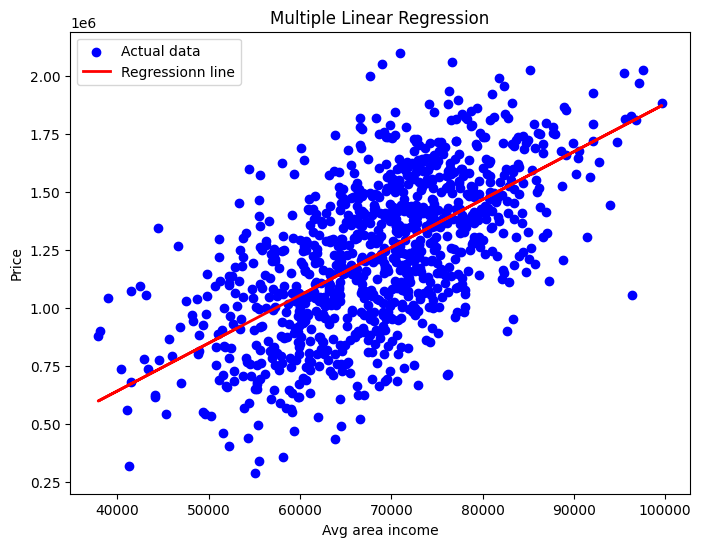

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(X_test,y_test,color='blue',label='Actual data')
plt.plot(X_test,y_pred,color='red',linewidth=2,label='Regressionn line')
plt.xlabel("Avg area income")
plt.ylabel("Price")
plt.title("Multiple Linear Regression")
plt.legend()
plt.show()